# 使用图卷积网络对用户分类

In [24]:
import pandas as pd
from tqdm import tqdm
import json
import os
import umap # pip install umap-learn
import numpy as np
import scipy.sparse as sp
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelBinarizer
from sklearn.metrics import f1_score, roc_auc_score, average_precision_score, confusion_matrix


import stellargraph as sg
from stellargraph.mapper import FullBatchNodeGenerator
from stellargraph.layer import GCN

import warnings
import tensorflow as tf
from tensorflow.keras import backend as K
from tensorflow.keras import activations, initializers, constraints, regularizers
from tensorflow.keras.layers import Input, Layer, Lambda, Dropout, Reshape, Dense
from tensorflow.keras.callbacks import EarlyStopping

from tensorflow.keras import layers, optimizers, losses, metrics, Model
import matplotlib.pyplot as plt
import seaborn as sns
%matplotlib inline

## 图卷积网络/Graph Convolutional Networks

GCN是一种处理图形态数据的神经网络结构。GCN的主要目标是将图和节点的属性信息提取到向量节点表示中。下面的例子中，我们将探讨GCNs如何实现这一点，并将应用此方法将Github开发人员分为web或ML工程师。类似的方法用在风控中，也是在图数据中将正常用户和欺诈用户分开。

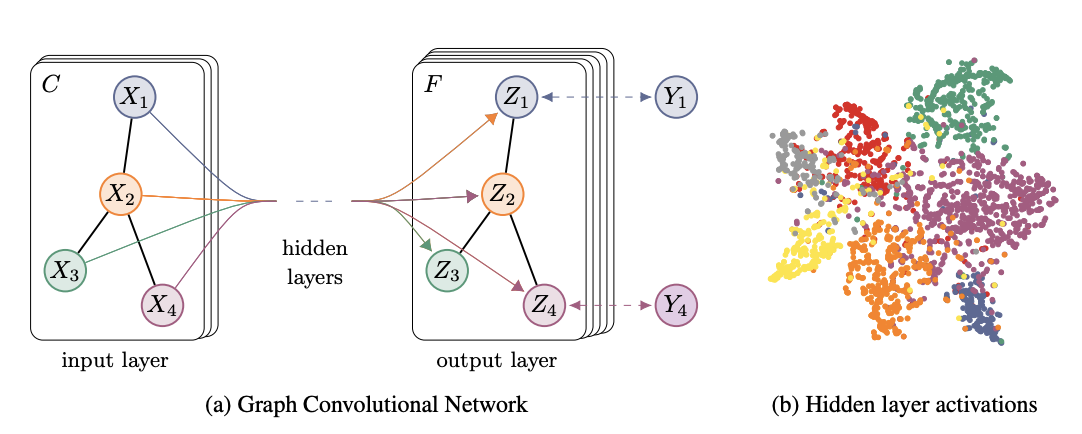

下面的实现将大量使用`stellargraph`库（[docs](https://stellargraph.readthedocs.io/en/stable/))。你可以在[这里](https://stellargraph.readthedocs.io/en/stable/demos/node-classification/gcn-node-classification.html)找到一些应用示例。

## 数据

我们将把github用户分为web或ML开发人员。在这个数据集中，节点是至少有10个项目库的github开发人员，连接的边表示相互关注，我们基于位置、点赞项目库、雇主和电子邮件来构建特征。

### 读取图(边/特征/标签)

In [4]:
edges_path = 'data/github/git_edges.csv'
targets_path = 'data/github/git_target.csv'
features_path = 'data/github/git_features.json'

In [5]:
# Read in edges
edges = pd.read_csv(edges_path)
edges.columns = ['source', 'target'] # renaming for StellarGraph compatibility
display(edges.shape, edges.head())

(289003, 2)

,source,target
0,0,23977
1,1,34526
2,1,2370
3,1,14683
4,1,29982


In [6]:
# Read in features
with open(features_path) as json_data:
    features = json.load(json_data)
    
max_feature = np.max([v for v_list in features.values() for v in v_list])
features_matrix = np.zeros(shape = (len(list(features.keys())), max_feature+1))

i = 0
for k, vs in tqdm(features.items()):
    for v in vs:
        features_matrix[i, v] = 1
    i+=1

Python(34976) MallocStackLogging: can't turn off malloc stack logging because it was not enabled.
100%|██████████| 37700/37700 [00:00<00:00, 117594.89it/s]


In [7]:
node_features = pd.DataFrame(features_matrix, index = features.keys())
display(node_features.shape, node_features.head())

(37700, 4005)

,0,1,2,3,4,5,6,7,8,9,...,3995,3996,3997,3998,3999,4000,4001,4002,4003,4004
0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
1,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
2,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
3,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0
4,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0


In [8]:
# Read in targets
targets = pd.read_csv(targets_path)
targets.index = targets.id.astype(str)
targets = targets.loc[features.keys(), :]
display(targets.shape, targets.head(), targets.ml_target.value_counts(normalize=True))

(37700, 3)

,id,name,ml_target
id,,,
0,0,Eiryyy,0
1,1,shawflying,0
2,2,JpMCarrilho,1
3,3,SuhwanCha,0
4,4,sunilangadi2,1


ml_target
0    0.741671
1    0.258329
Name: proportion, dtype: float64

因此，我们有37700个开发人员，289003个相互关注，每个节点4005个特征。总体数据中大约75%的用户是web开发人员，25%是ML开发人员。

### 转换为StellarGraph数据形态

我们后续建模需要先构建`stellargraph`支持的图形数据结构。将数据转换为StellarGraph非常简单，只需向`StellarGraph`提供节点特征和边DataFrame数据。它实际的功能强大很多，还支持加权边、异构节点和边类型以及有向图。

In [9]:
G = sg.StellarGraph(node_features, edges.astype(str))

In [10]:
print(G.info())

StellarGraph: Undirected multigraph
 Nodes: 37700, Edges: 289003

 Node types:
  default: [37700]
    Features: float32 vector, length 4005
    Edge types: default-default->default

 Edge types:
    default-default->default: [289003]
        Weights: all 1 (default)
        Features: none


### 训练集/验证集/测试集 切分

我们在机器学习任务中，希望了解自己的模型效果到底如何，我们会把数据切分成训练集、验证集和测试集。GCN是一个半监督模型，这意味着它需要的标签明显少于纯监督模型（如随机森林）。假如在我们的数据集中，我们只有1%的数据被标记，这大约是400个开发者。我们将使用200名开发人员样本进行训练，并使用200名开发人员样本进行验证。剩下的用于测试。

In [11]:
train_pages, test_pages = train_test_split(targets, train_size=200)
val_pages, test_pages = train_test_split(test_pages, train_size=200)

In [12]:
train_pages.shape, val_pages.shape, test_pages.shape

((200, 3), (200, 3), (37300, 3))

## 预处理

### 标签预处理

In [13]:
target_encoding = LabelBinarizer()

train_targets = target_encoding.fit_transform(train_pages['ml_target'])
val_targets = target_encoding.transform(val_pages['ml_target'])
test_targets = target_encoding.transform(test_pages['ml_target'])

### 图数据预处理

图数据的预处理是GCNs工作的关键。为了理解我们需要做什么样的预处理，我们思考一下图卷积层将要做什么。我们想要的是以某种方式聚集来自相邻节点的特征信息，因为我们想要学习反映图形邻域的embedding。应用在图像数据的卷积神经网络，卷积操作是通过对输入像素用卷积核进行卷积运算来实现的。但是图像数据非常规则，矩形形态的输入能保证卷积核处理的输入大小是固定的形状。而在图形态的数据中，并不能保证这一点，因此我们需要对数据做一些预处理。

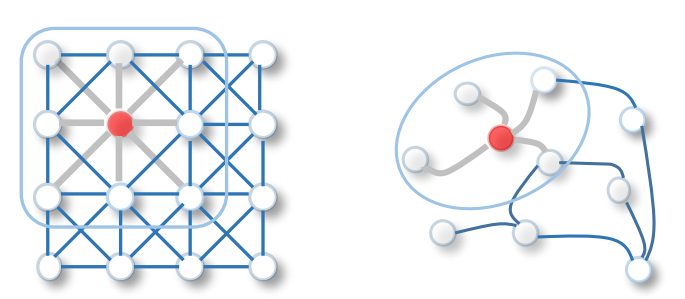

这里的处理方法是利用信息传递的思想，将隐藏状态乘以邻接矩阵。

通过将隐层状态（或第一层中的节点特征）乘以它，我们在某种程度上应用了一个掩码并仅聚合来自相邻节点的信息。

图卷积层可以用以下的公式来表示：

\begin{equation} 
H^{(l+1)} = \sigma(\tilde{D}^{-1/2}\tilde{A}\tilde{D}^{-1/2}{H^{(l)}}{W^{(l)}})
\end{equation}

这个公式中：
* $H$ - 隐层 (or node attributes when $l$ = 0)
* $\tilde{D}$ - degree matrix/度矩阵
* $\tilde{A}$ - adjacency matrix/邻接矩阵
* $W$ - trainable weights/模型权重
* $\sigma$ - activation function/激活函数
* ${l}$ - layer number/层数

大家观察到上述公式有两个部分：不可训练（D，A）和可训练（H，A）。非训练部分称为归一化邻接矩阵。如果我们仔细观察，会发现如果我们移除了不可训练的部分，我们就剩下了简单的dense/全连接层。通过将隐状态与归一化邻接矩阵相乘，可以起到一个聚集相邻特征的作用。这里要多说一点的是，之所以我们要用归一化的邻接矩阵，是我们希望从高度连接的节点中减少节点特性（或隐藏状态）的“贡献”，因为它们并不重要。

In [14]:
# Get the adjacency matrix
A = G.to_adjacency_matrix(weighted=False)

# Add self-connections
A_t = A + sp.diags(np.ones(A.shape[0]) - A.diagonal())

# Degree matrix to the power of -1/2
D_t = sp.diags(np.power(np.array(A.sum(1)), -0.5).flatten(), 0)

# Normalise the Adjacency matrix
A_norm = A.dot(D_t).transpose().dot(D_t).todense()

我们通过上述的过程就完成了GCN的数据预处理了。在实际建模之前，我们还有一些工作需要做：
1. 提取训练集、验证集、测试集的数据切片下标，模型在计算损失的时候会需要
2. 调整一下我们的数据维度(对标签增加一个维度)，这是keras建模需要的

In [15]:
# Define the function to get these indices
def get_node_indices(G, ids):
    # find the indices of the nodes
    node_ids = np.asarray(ids)
    flat_node_ids = node_ids.reshape(-1)

    flat_node_indices = G.node_ids_to_ilocs(flat_node_ids) # in-built function makes it really easy
    # back to the original shape
    node_indices = flat_node_indices.reshape(1, len(node_ids)) # add 1 extra dimension
    
    return node_indices

train_indices = get_node_indices(G, train_pages.index)
val_indices = get_node_indices(G, val_pages.index)
test_indices = get_node_indices(G, test_pages.index)

In [16]:
# Expand dimensions
features_input = np.expand_dims(features_matrix, 0)
A_input = np.expand_dims(A_norm, 0)

y_train = np.expand_dims(train_targets, 0)
y_val = np.expand_dims(val_targets, 0)
y_test = np.expand_dims(test_targets, 0)

下面就可以开始建模了

## GCN建模

我们在上面的内容中可以看出来，GCN神经网络层只不过是输入、权重和归一化的邻接矩阵的乘法。有兴趣大家可以直接去github的`stellargraph`中的`GraphConVololution`层[实现](https://github.com/stellargraph/stellargraph/blob/develd/stellargraph/layer/gcn.py)里208到209行查看。我们在下面的代码里会直接使用这个层次。

In [17]:
from stellargraph.layer.gcn import GraphConvolution, GatherIndices

In [18]:
# Initialise GCN parameters
kernel_initializer="glorot_uniform"
bias = True
bias_initializer="zeros"
n_layers = 2
layer_sizes = [32, 32]
dropout = 0.5
n_features = features_input.shape[2]
n_nodes = features_input.shape[1]

我们初始化Input层，并对以下数据接受正确的数据维度：
1. Features matrix/特征矩阵
2. Train/Val/Test indices / 训练集、验证集、测试集
3. Normalised adjacency matrix/归一化的邻接矩阵

In [20]:
x_features = Input(batch_shape=(1, n_nodes, n_features))
x_indices = Input(batch_shape=(1, None), dtype="int32")
x_adjacency = Input(batch_shape=(1, n_nodes, n_nodes))
x_inp = [x_features, x_indices, x_adjacency]
x_inp

[<KerasTensor shape=(1, 37700, 4005), dtype=float32, sparse=False, ragged=False, name=keras_tensor>,
 <KerasTensor shape=(1, None), dtype=int32, sparse=False, ragged=False, name=keras_tensor_1>,
 <KerasTensor shape=(1, 37700, 37700), dtype=float32, sparse=False, ragged=False, name=keras_tensor_2>]

现在，我们可以建立一个有2个GCN层的模型，我们在中间加上dropout以提高模型的泛化能力。

In [21]:
x = Dropout(0.5)(x_features)
x = GraphConvolution(32, activation='relu', 
                     use_bias=True,
                     kernel_initializer=kernel_initializer,
                     bias_initializer=bias_initializer)([x, x_adjacency])
x = Dropout(0.5)(x)
x = GraphConvolution(32, activation='relu', 
                     use_bias=True,
                     kernel_initializer=kernel_initializer,
                     bias_initializer=bias_initializer)([x, x_adjacency])

x = GatherIndices(batch_dims=1)([x, x_indices])
output = Dense(1, activation='sigmoid')(x)

In [22]:
model = Model(inputs=[x_features, x_indices, x_adjacency], outputs=output)
model.summary()

Model: "functional"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ input_layer         │ (1, 37700, 4005)  │          0 │ -                 │
│ (InputLayer)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dropout_1 (Dropout) │ (1, 37700, 4005)  │          0 │ input_layer[0][0] │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ input_layer_2       │ (1, 37700, 37700) │          0 │ -                 │
│ (InputLayer)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ graph_convolution   │ (1, 37700, 32)    │    128,192 │ dropout_1[0][0],  │
│ (GraphConvolution)  │                   │            │ input_layer_2[0]… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dropout_2 (Dropout) │ (1, 37700, 32)    │          0 │ graph_convolutio… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ graph_convolution_1 │ (1, 37700, 32)    │      1,056 │ dropout_2[0][0],  │
│ (GraphConvolution)  │                   │            │ input_layer_2[0]… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ input_layer_1       │ (1, None)         │          0 │ -                 │
│ (InputLayer)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ gather_indices      │ (1, None, 32)     │          0 │ graph_convolutio… │
│ (GatherIndices)     │                   │            │ input_layer_1[0]… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense (Dense)       │ (1, None, 1)      │         33 │ gather_indices[0… │
└─────────────────────┴───────────────────┴────────────┴───────────────────┘

 Total params: 129,281 (505.00 KB)

 Trainable params: 129,281 (505.00 KB)

 Non-trainable params: 0 (0.00 B)

In [26]:
model.compile(
    optimizer=optimizers.Adam(learning_rate=0.01),
    loss=losses.binary_crossentropy,
    metrics=["acc"],
)

In [27]:
es_callback = EarlyStopping(monitor="val_loss", patience=10, restore_best_weights=True)

In [29]:
# 训练周期epochs（原始200 -> 5，先用于跑通整个流程）
history = model.fit(
    x = [features_input, train_indices, A_input],
    y = y_train,
    batch_size = 32,
    epochs=5,
    validation_data=([features_input, val_indices, A_input], y_val),
    verbose=1,
    shuffle=False,
    callbacks=[es_callback],
)

Epoch 1/5
1/1 ━━━━━━━━━━━━━━━━━━━━ 480s 480s/step - acc: 0.8450 - loss: 0.3643 - val_acc: 0.8300 - val_loss: 0.4018
Epoch 2/5
1/1 ━━━━━━━━━━━━━━━━━━━━ 1668s 1668s/step - acc: 0.8500 - loss: 0.3523 - val_acc: 0.8250 - val_loss: 0.4015
Epoch 3/5
1/1 ━━━━━━━━━━━━━━━━━━━━ 2263s 2263s/step - acc: 0.8550 - loss: 0.3487 - val_acc: 0.8250 - val_loss: 0.4041
Epoch 4/5
1/1 ━━━━━━━━━━━━━━━━━━━━ 187s 187s/step - acc: 0.8600 - loss: 0.3453 - val_acc: 0.8300 - val_loss: 0.4074
Epoch 5/5
1/1 ━━━━━━━━━━━━━━━━━━━━ 73s 73s/step - acc: 0.8500 - loss: 0.3323 - val_acc: 0.8300 - val_loss: 0.4090


## 模型评估
我们在训练好模型以后，可以在测试集上测试它的效果。

In [30]:
test_preds = model.predict([features_input, test_indices, A_input])

1/1 ━━━━━━━━━━━━━━━━━━━━ 88s 88s/step


In [31]:
def evaluate_preds(true, pred):
    auc = roc_auc_score(true, pred)
    pr = average_precision_score(true, pred)
    bin_pred = [1 if p > 0.5 else 0 for p in pred]
    f_score = f1_score(true, bin_pred)
    print('ROC AUC:', auc)
    print('PR AUC:', pr)
    print('F1 score:', f_score)
    print(confusion_matrix(true, bin_pred, normalize='true'))
    
    return auc, pr, f_score

In [32]:
auc, pr, f_score = evaluate_preds(test_targets.ravel(),test_preds[0].ravel())

ROC AUC: 0.8728297371229181
PR AUC: 0.7357496369681144
F1 score: 0.4932983901160614
[[0.9849219  0.0150781 ]
 [0.65844048 0.34155952]]


我们在200个测试样本上得到的ROC AUC得分为0.89，效果还不错。我们把送入最后分类层之前的embedding取出来做一下可视化，看看我们的样本分布和分类情况。

In [33]:
embedding_model = Model(inputs=x_inp, outputs=model.layers[-2].output)
all_indices = get_node_indices(G, targets.index)
emb = embedding_model.predict([features_input, all_indices, A_input])
emb.shape

1/1 ━━━━━━━━━━━━━━━━━━━━ 58s 58s/step


(1, 37700, 32)

In [34]:
u = umap.UMAP(random_state=42)
umap_embs = u.fit_transform(emb[0])

/Users/ziyi/Downloads/风控项目8-数据代码/.venv/lib/python3.13/site-packages/umap/umap_.py:1952: UserWarning: n_jobs value 1 overridden to 1 by setting random_state. Use no seed for parallelism.
  warn(
/Users/ziyi/Downloads/风控项目8-数据代码/.venv/lib/python3.13/site-packages/umap/spectral.py:548: UserWarning: Spectral initialisation failed! The eigenvector solver
failed. This is likely due to too small an eigengap. Consider
adding some noise or jitter to your data.

Falling back to random initialisation!
  warn(


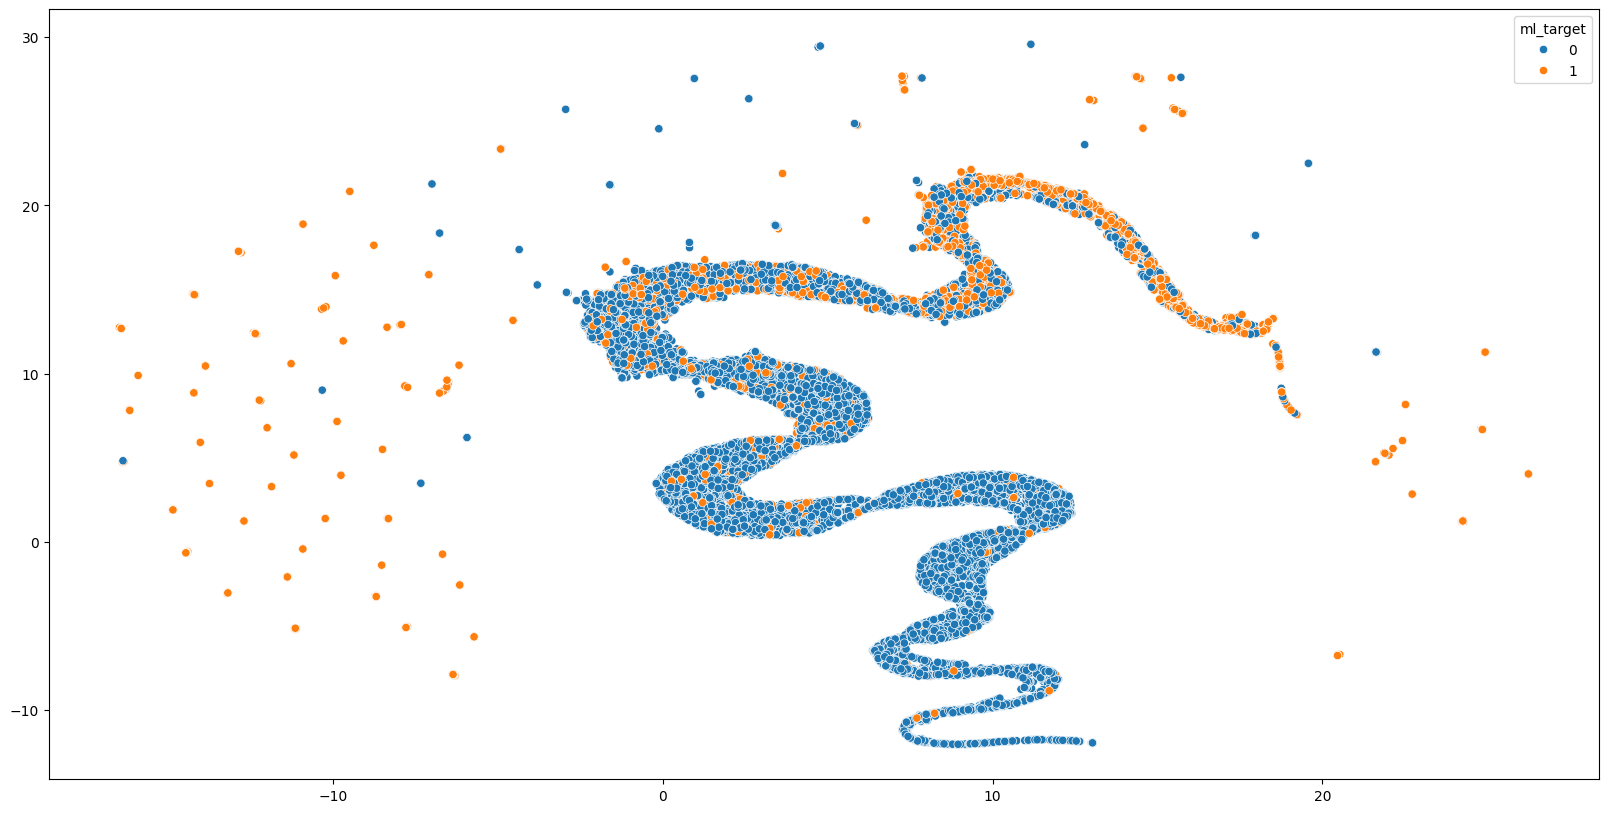

In [35]:
plt.figure(figsize=(20,10))
ax = sns.scatterplot(x = umap_embs[:, 0], y = umap_embs[:, 1], hue = targets['ml_target'])

我们在图上可以看到，经过GCN模型的学习，两个不同的类对应的数据点被尽量分到了两侧。虽然在中间的部分有一些混合，其实也可以理解，因为ML和web开发人员也有很多共同点。同时，在更大规模的数据上，效果会更明显一些。

## 对比随机森林

作为对比，我们还可以把节点的feature送入随机森林学习分类看看效果。

In [36]:
from sklearn.ensemble import RandomForestClassifier

In [37]:
rf = RandomForestClassifier()

rf.fit(node_features.loc[train_pages.index, :], train_targets.ravel())

test_preds = rf.predict_proba(node_features.loc[test_pages.index, :])[:, 1]
evaluate_preds(test_targets.ravel(), test_preds)

ROC AUC: 0.8267611463321314
PR AUC: 0.6826275498088147
F1 score: 0.27730211427572954
[[0.99222592 0.00777408]
 [0.83544173 0.16455827]]


(0.8267611463321314, 0.6826275498088147, 0.27730211427572954)

我们可以看到，相比于随机森林，GCN确实有更好的auc结果，提升了0.04，说明我们的神经网络确实捕获到了更多的信息。

## 追加更多的数据

我们把训练数据提升到1000个标注的样本，看看效果变化。（在实际工作中，更充足的数据一般都有更好的信息支撑度，能得出更好的结果）

In [38]:
# 1000 training examples
train_pages, test_pages = train_test_split(targets, train_size=1000)
val_pages, test_pages = train_test_split(test_pages, train_size=500)

train_targets = target_encoding.fit_transform(train_pages['ml_target'])
val_targets = target_encoding.transform(val_pages['ml_target'])
test_targets = target_encoding.transform(test_pages['ml_target'])

我们可以用`BatchGenerator`类初始化一个数据生成器，更好地对大数据进行建模

In [44]:
# Initialise the generator
generator = FullBatchNodeGenerator(G, method="gcn")

# Use the .flow method to prepare it for use with GCN
train_gen = generator.flow(train_pages.index, train_targets)
val_gen = generator.flow(val_pages.index, val_targets)
test_gen = generator.flow(test_pages.index, test_targets)

Using GCN (local pooling) filters...


使用`stellargraph`构建一个GCN网络

In [45]:
# Build necessary layers
gcn = GCN(
    layer_sizes=[32, 32], activations=["relu", "relu"], generator=generator, dropout=0.5
)

# Access the input and output tensors
x_inp, x_out = gcn.in_out_tensors()

# Pass the output tensor through the dense layer with sigmoid
predictions = layers.Dense(units=train_targets.shape[1], activation="sigmoid")(x_out)

In [46]:
model = Model(inputs=x_inp, outputs=predictions)
model.compile(
    optimizer=optimizers.Adam(learning_rate=0.01),
    loss=losses.binary_crossentropy,
    metrics=["acc"],
)

和之前一样的方式进行模型训练，大家要稍微注意一下的是，这里我们是使用`generator`作为数据生成器把数据逐步喂给模型学习的。

In [47]:
history = model.fit(
    train_gen,
    epochs=200,
    validation_data=val_gen,
    verbose=2,
    shuffle=False,  # this should be False, since shuffling data means shuffling the whole graph
    callbacks=[es_callback],
)

/Users/ziyi/Downloads/风控项目8-数据代码/.venv/lib/python3.13/site-packages/keras/src/trainers/data_adapters/py_dataset_adapter.py:121: UserWarning: Your `PyDataset` class should call `super().__init__(**kwargs)` in its constructor. `**kwargs` can include `workers`, `use_multiprocessing`, `max_queue_size`. Do not pass these arguments to `fit()`, as they will be ignored.
  self._warn_if_super_not_called()


TypeError: `output_signature` must contain objects that are subclass of `tf.TypeSpec` but found <class 'list'> which is not.

我们在测试集上再看看现在的效果

In [60]:
new_preds = model.predict(test_gen)

In [61]:
auc, pr, f_score = evaluate_preds(test_targets.ravel(),new_preds[0].ravel())

ROC AUC: 0.8967718089804773
PR AUC: 0.7643095230146493
F1 score: 0.7103994490358128
[[0.92937979 0.07062021]
 [0.33722425 0.66277575]]


现在的测试集上的表现，比之前200个样本上的模型表现更优秀，我们在实际应用的时候，应该尽量多地提供足量数据给模型学习。

## 总结

GCNs是一种功能强大的深层神经网络体系结构，能帮助我们在图这种关联数据上，把已有特征和图形邻域信息结合起来进行学习和预估。大家在很多业务场景下，包括风控场景，如果获取用户的关联信息，都可以基于图神经网络进行分类尝试。